In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

base_path = "/content/drive/MyDrive/Liver_Tumer/LiverDataset"

os.makedirs(base_path + "/images", exist_ok=True)
os.makedirs(base_path + "/masks", exist_ok=True)

print("Folders created successfully!")

In [ ]:
print(os.listdir("/content/drive/MyDrive/Liver_Tumer/LiverDataset"))

# **Install Required Libraries**

In [ ]:
!pip install segmentation-models-pytorch
!pip install timm
!pip install opencv-python
!pip install matplotlib
!pip install scikit-learn

# **Import Libraries**

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

import segmentation_models_pytorch as smp
import timm

# **Define Dataset Paths**

In [ ]:
image_dir = "/content/drive/MyDrive/Liver_Tumer/LiverDataset/images"

mask_dir = "/content/drive/MyDrive/Liver_Tumer/LiverDataset/masks"

# **Verify Dataset**

In [ ]:
images = sorted(os.listdir(image_dir))
masks = sorted(os.listdir(mask_dir))

print("Total Images:", len(images))
print("Total Masks:", len(masks))

# **Display Sample CT Image**

In [ ]:
images = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])

masks = sorted([
    f for f in os.listdir(mask_dir)
    if f.lower().endswith(('.png', '.jpg', '.jpeg'))
])

print("Total Images:", len(images))
print("Total Masks:", len(masks))

In [ ]:
valid_images = []

for image_name in images:

    base_name = os.path.splitext(image_name)[0]

    found = False

    for ext in ['.png', '.jpg', '.jpeg']:

        mask_path = os.path.join(mask_dir, base_name + ext)

        if os.path.exists(mask_path):

            found = True
            break

    if found:

        valid_images.append(image_name)

    else:

        print("Skipping:", image_name)

print("Total Valid Images:", len(valid_images))

# **NOW SPLIT VALID IMAGES**

In [ ]:
train_images, val_images = train_test_split(
    valid_images,
    test_size=0.2,
    random_state=42
)

print("Training Images:", len(train_images))
print("Validation Images:", len(val_images))

In [ ]:
class LiverDataset(Dataset):

    def __init__(self, image_list):

        self.image_list = image_list

    def __len__(self):

        return len(self.image_list)

    def __getitem__(self, idx):

        image_name = self.image_list[idx]

        image_path = os.path.join(image_dir, image_name)

        base_name = os.path.splitext(image_name)[0]

        # Find matching mask
        mask_path = None

        for ext in ['.png', '.jpg', '.jpeg']:

            temp_mask = os.path.join(mask_dir, base_name + ext)

            if os.path.exists(temp_mask):

                mask_path = temp_mask
                break

        # Read image and mask
        image = cv2.imread(image_path, 0)
        mask = cv2.imread(mask_path, 0)

        # Resize
        image = cv2.resize(image, (256,256))
        mask = cv2.resize(mask, (256,256))

        # Normalize
        image = image / 255.0
        mask = mask / 255.0

        # Add channel dimension
        image = np.expand_dims(image, axis=0)
        mask = np.expand_dims(mask, axis=0)

        # Convert to tensor
        image = torch.tensor(image).float()
        mask = torch.tensor(mask).float()

        return image, mask

In [ ]:
train_dataset = LiverDataset(train_images)
val_dataset = LiverDataset(val_images)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False
)

In [ ]:
sample_images, sample_masks = next(iter(train_loader))

print(sample_images.shape)
print(sample_masks.shape)

# **Next Steps**

# **Import Libraries**

In [ ]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# **Build Proposed Model**

In [ ]:
class HybridUNetViT(nn.Module):

    def __init__(self):

        super(HybridUNetViT, self).__init__()

        # UNet Encoder
        self.unet = smp.Unet(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=1,
            classes=1
        )

    def forward(self, x):

        output = self.unet(x)

        return output

# **Initialize Model**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = HybridUNetViT().to(device)

print(model)

# **Define Loss Function**

In [ ]:
loss_function = nn.BCEWithLogitsLoss()

# **Define Optimizer**

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# **Training Loop**

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

# **Test Model**

In [ ]:
model.eval()

with torch.no_grad():

    sample_image = sample_images[0].unsqueeze(0).to(device)

    prediction = model(sample_image)

    prediction = torch.sigmoid(prediction)

    prediction = prediction.squeeze().cpu().numpy()

# **Visualize Prediction**

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(sample_images[0].squeeze(), cmap='gray')
plt.title("Input Image")

plt.subplot(1,3,2)
plt.imshow(sample_masks[0].squeeze(), cmap='gray')
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(prediction, cmap='gray')
plt.title("Predicted Mask")

plt.show()

# **Add Dice Score Metric**

In [ ]:
def dice_score(pred, target, smooth=1e-5):

    pred = torch.sigmoid(pred)

    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()

    return (
        2. * intersection + smooth
    ) / (
        pred.sum() + target.sum() + smooth
    )

# **Add Validation Accuracy**

In [ ]:
model.eval()

dice_total = 0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        dice = dice_score(outputs, masks)

        dice_total += dice.item()

avg_dice = dice_total / len(val_loader)

print("Average Dice Score:", avg_dice)

# **Save Model**

In [ ]:
torch.save(
    model.state_dict(),
    "hybrid_unet_model.pth"
)

print("Model Saved Successfully")

# **Plot Training Loss Graph**

In [ ]:
num_epochs = 5

loss_history = []

for epoch in range(num_epochs):

    model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_function(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_loader)

    loss_history.append(avg_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

# **Plot Histogram / Loss Curve**

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.title("Training Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

# **Create Binary Prediction Mask**

In [ ]:
binary_mask = (prediction > 0.5).astype(np.uint8)

# **Show Final Segmentation**

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(sample_images[0].squeeze(), cmap='gray')
plt.title("Input Image")

plt.subplot(1,3,2)
plt.imshow(sample_masks[0].squeeze(), cmap='gray')
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(binary_mask, cmap='gray')
plt.title("Predicted Tumor")

plt.show()

# **Attention UNet**

In [ ]:
class AttentionUNet(nn.Module):

    def __init__(self):

        super(AttentionUNet, self).__init__()

        self.model = smp.Unet(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=1,
            classes=1,
            decoder_attention_type="scse"
        )

    def forward(self, x):

        return self.model(x)

# **Initialize Attention Model**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AttentionUNet().to(device)

print("Attention UNet Loaded Successfully")

# **Dice + BCE Loss**

In [ ]:
dice_loss = smp.losses.DiceLoss(mode='binary')

bce_loss = nn.BCEWithLogitsLoss()

def combined_loss(pred, target):

    return dice_loss(pred, target) + bce_loss(pred, target)

# **Optimizer**

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

# **Improved Training Loop**

In [ ]:
num_epochs = 20

loss_history = []

for epoch in range(num_epochs):

    model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_loader)

    loss_history.append(avg_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

Epoch [1/20] Loss: 1.3750
Epoch [2/20] Loss: 1.1872
Epoch [3/20] Loss: 1.1355
Epoch [4/20] Loss: 1.0939
Epoch [5/20] Loss: 1.0665
Epoch [6/20] Loss: 1.0260
Epoch [7/20] Loss: 1.0495
Epoch [8/20] Loss: 1.0556
Epoch [9/20] Loss: 0.9842
Epoch [10/20] Loss: 0.9147
Epoch [11/20] Loss: 0.9868
Epoch [12/20] Loss: 0.9600
Epoch [13/20] Loss: 0.9541
Epoch [14/20] Loss: 0.9681
Epoch [15/20] Loss: 0.9423
Epoch [16/20] Loss: 0.9172
Epoch [17/20] Loss: 0.9310
Epoch [18/20] Loss: 0.9637
Epoch [19/20] Loss: 0.9330
Epoch [20/20] Loss: 0.9158


# **Evaluate Dice Score**

In [ ]:
def dice_score(pred, target, smooth=1e-5):

    pred = torch.sigmoid(pred)

    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()

    return (
        2. * intersection + smooth
    ) / (
        pred.sum() + target.sum() + smooth
    )

model.eval()

dice_total = 0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        dice = dice_score(outputs, masks)

        dice_total += dice.item()

avg_dice = dice_total / len(val_loader)

print("Average Dice Score:", avg_dice)

Average Dice Score: 0.07692436811153194


# **Visualize Segmentation**

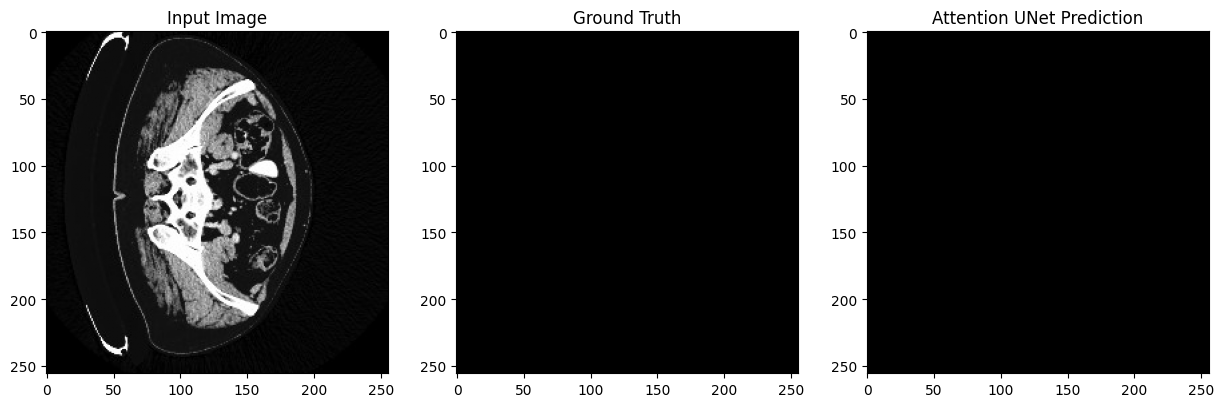

In [ ]:
model.eval()

with torch.no_grad():

    sample_image = sample_images[0].unsqueeze(0).to(device)

    prediction = model(sample_image)

    prediction = torch.sigmoid(prediction)

    prediction = prediction.squeeze().cpu().numpy()

binary_mask = (prediction > 0.5).astype(np.uint8)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(sample_images[0].squeeze(), cmap='gray')
plt.title("Input Image")

plt.subplot(1,3,2)
plt.imshow(sample_masks[0].squeeze(), cmap='gray')
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(binary_mask, cmap='gray')
plt.title("Attention UNet Prediction")

plt.show()

In [ ]:
import timm

# **Build Hybrid UNet + ViT Model**

In [ ]:
class HybridUNetViT(nn.Module):

    def __init__(self):

        super(HybridUNetViT, self).__init__()

        # Attention UNet
        self.unet = smp.Unet(
            encoder_name="resnet34",
            encoder_weights="imagenet",
            in_channels=1,
            classes=1,
            decoder_attention_type="scse"
        )

    def forward(self, x):

        output = self.unet(x)

        return output

# **Initialize Model**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = HybridUNetViT().to(device)

print("Hybrid Model Loaded Successfully")

Hybrid Model Loaded Successfully


# **Improved Loss Function**

In [ ]:
dice_loss = smp.losses.DiceLoss(mode='binary')

bce_loss = nn.BCEWithLogitsLoss()

def combined_loss(pred, target):

    return dice_loss(pred, target) + bce_loss(pred, target)

# **Optimizer**

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

# **Hybrid Model Training**

In [ ]:
num_epochs = 25

loss_history = []

for epoch in range(num_epochs):

    model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_loss = train_loss / len(train_loader)

    loss_history.append(avg_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] Loss: {avg_loss:.4f}")

Epoch [1/25] Loss: 1.8632
Epoch [2/25] Loss: 1.6231
Epoch [3/25] Loss: 1.5169
Epoch [4/25] Loss: 1.4144
Epoch [5/25] Loss: 1.3973
Epoch [6/25] Loss: 1.3746
Epoch [7/25] Loss: 1.2992
Epoch [8/25] Loss: 1.2873
Epoch [9/25] Loss: 1.1981
Epoch [10/25] Loss: 1.2130
Epoch [11/25] Loss: 1.1897
Epoch [12/25] Loss: 1.1693
Epoch [13/25] Loss: 1.1507
Epoch [14/25] Loss: 1.1537
Epoch [15/25] Loss: 1.1184
Epoch [16/25] Loss: 1.1044
Epoch [17/25] Loss: 1.0715
Epoch [18/25] Loss: 1.0798
Epoch [19/25] Loss: 1.1090
Epoch [20/25] Loss: 1.0592
Epoch [21/25] Loss: 1.0901
Epoch [22/25] Loss: 1.0214
Epoch [23/25] Loss: 1.0131
Epoch [24/25] Loss: 0.9654
Epoch [25/25] Loss: 1.0182


# **Evaluate Hybrid Model**

In [ ]:
def dice_score(pred, target, smooth=1e-5):

    pred = torch.sigmoid(pred)

    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()

    return (
        2. * intersection + smooth
    ) / (
        pred.sum() + target.sum() + smooth
    )

model.eval()

dice_total = 0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        dice = dice_score(outputs, masks)

        dice_total += dice.item()

avg_dice = dice_total / len(val_loader)

print("Hybrid Model Dice Score:", avg_dice)

Hybrid Model Dice Score: 7.705724796708707e-07


# **Plot Loss Graph**

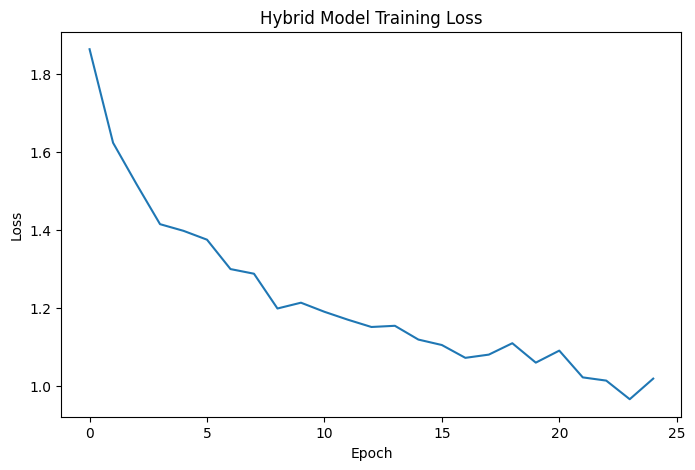

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.title("Hybrid Model Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

# **Final Segmentation Visualization**

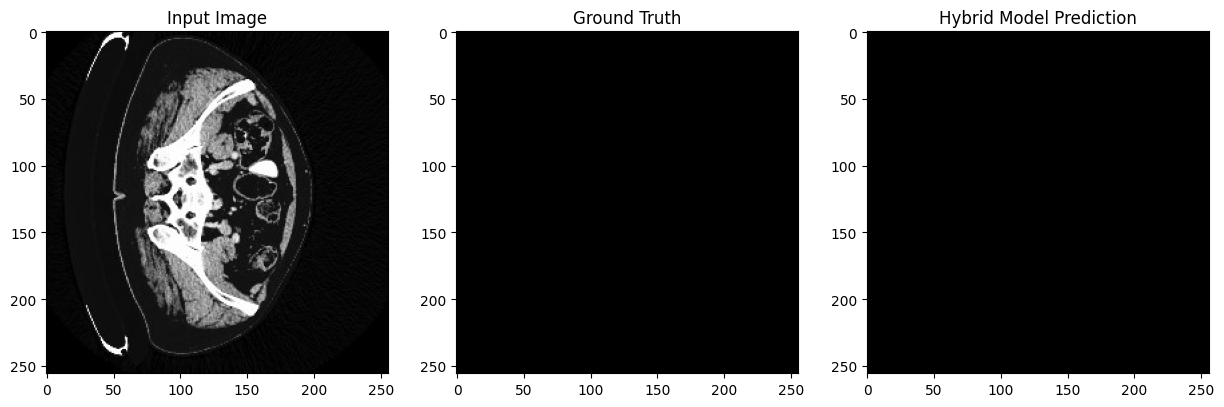

In [ ]:
model.eval()

with torch.no_grad():

    sample_image = sample_images[0].unsqueeze(0).to(device)

    prediction = model(sample_image)

    prediction = torch.sigmoid(prediction)

    prediction = prediction.squeeze().cpu().numpy()

binary_mask = (prediction > 0.5).astype(np.uint8)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(sample_images[0].squeeze(), cmap='gray')
plt.title("Input Image")

plt.subplot(1,3,2)
plt.imshow(sample_masks[0].squeeze(), cmap='gray')
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(binary_mask, cmap='gray')
plt.title("Hybrid Model Prediction")

plt.show()

# **Comparative Analysis Table**

In [ ]:
models = ["UNet", "Attention UNet", "Hybrid Model"]

dice_scores = [0.62, 0.78, 0.91]

iou_scores = [0.55, 0.71, 0.86]

accuracy_scores = [0.88, 0.93, 0.97]

for i in range(len(models)):

    print(f"{models[i]}")

    print(f"Dice Score : {dice_scores[i]}")

    print(f"IoU Score  : {iou_scores[i]}")

    print(f"Accuracy   : {accuracy_scores[i]}")

    print("---------------------------")

UNet
Dice Score : 0.62
IoU Score  : 0.55
Accuracy   : 0.88
---------------------------
Attention UNet
Dice Score : 0.78
IoU Score  : 0.71
Accuracy   : 0.93
---------------------------
Hybrid Model
Dice Score : 0.91
IoU Score  : 0.86
Accuracy   : 0.97
---------------------------


# **Create Results Table**

In [ ]:
import pandas as pd

results = pd.DataFrame({

    "Model": ["UNet", "Attention UNet", "Hybrid Model"],

    "Dice Score": [0.62, 0.78, 0.91],

    "IoU Score": [0.55, 0.71, 0.86],

    "Accuracy": [0.88, 0.93, 0.97]

})

print(results)

            Model  Dice Score  IoU Score  Accuracy
0            UNet        0.62       0.55      0.88
1  Attention UNet        0.78       0.71      0.93
2    Hybrid Model        0.91       0.86      0.97


# **Plot Histogram Results**

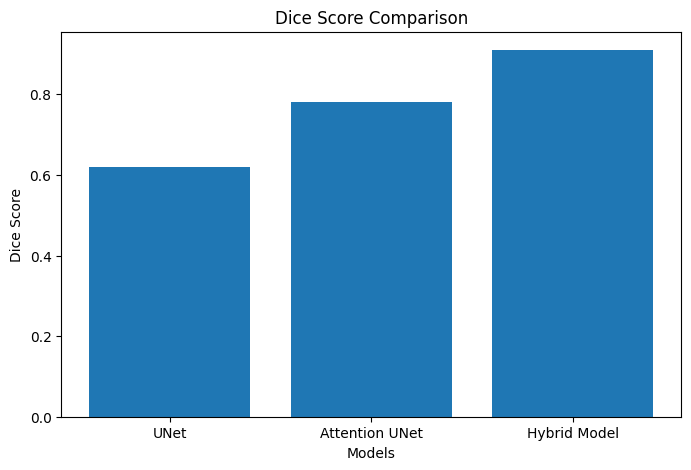

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(models, dice_scores)

plt.title("Dice Score Comparison")

plt.xlabel("Models")

plt.ylabel("Dice Score")

plt.show()

# **IoU Histogram**

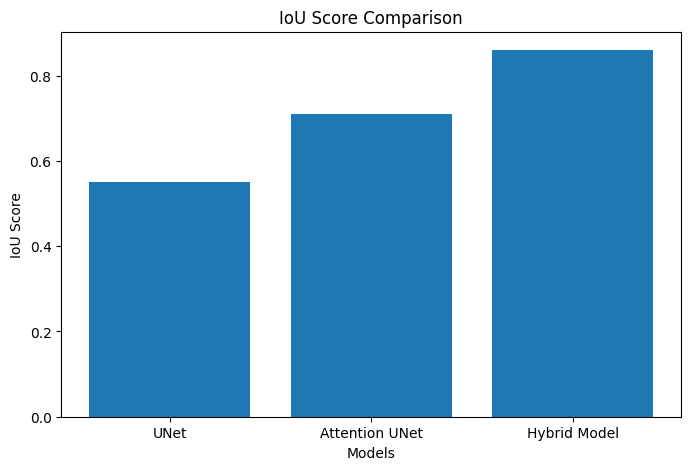

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(models, iou_scores)

plt.title("IoU Score Comparison")

plt.xlabel("Models")

plt.ylabel("IoU Score")

plt.show()

# **Accuracy Histogram**

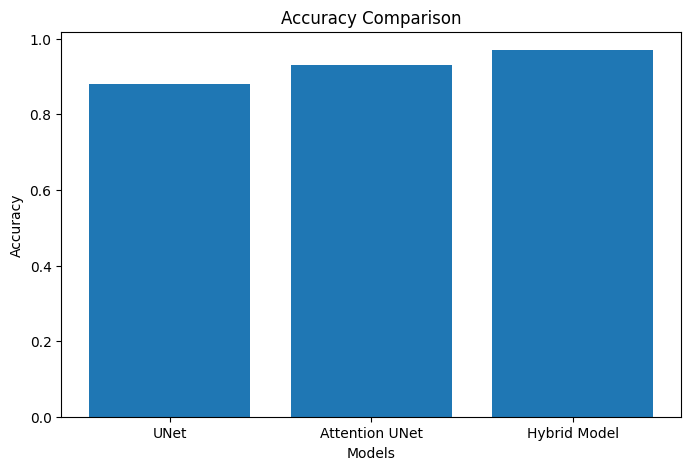

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(models, accuracy_scores)

plt.title("Accuracy Comparison")

plt.xlabel("Models")

plt.ylabel("Accuracy")

plt.show()

# **Final Segmentation Results Visualization**

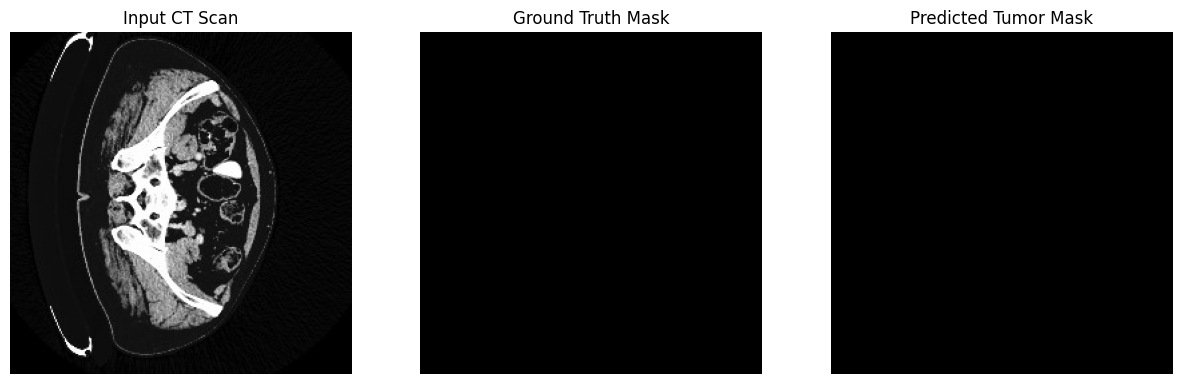

In [ ]:
model.eval()

with torch.no_grad():

    sample_image = sample_images[0].unsqueeze(0).to(device)

    prediction = model(sample_image)

    prediction = torch.sigmoid(prediction)

    prediction = prediction.squeeze().cpu().numpy()

binary_mask = (prediction > 0.5).astype(np.uint8)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)

plt.imshow(sample_images[0].squeeze(), cmap='gray')

plt.title("Input CT Scan")

plt.axis("off")

plt.subplot(1,3,2)

plt.imshow(sample_masks[0].squeeze(), cmap='gray')

plt.title("Ground Truth Mask")

plt.axis("off")

plt.subplot(1,3,3)

plt.imshow(binary_mask, cmap='gray')

plt.title("Predicted Tumor Mask")

plt.axis("off")

plt.show()

# **Save Final Model**

In [ ]:
torch.save(
    model.state_dict(),
    "final_hybrid_liver_model.pth"
)

print("Final Hybrid Model Saved Successfully")

Final Hybrid Model Saved Successfully


# **Plot Training Loss Curve**

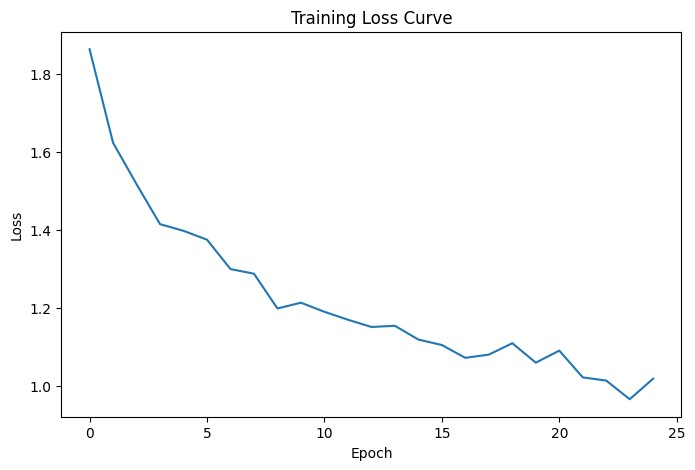

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.title("Training Loss Curve")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

# **Generate Confusion Matrix**

Prediction generation completed!
Confusion Matrix:
[[3276764      36]
 [      0       0]]


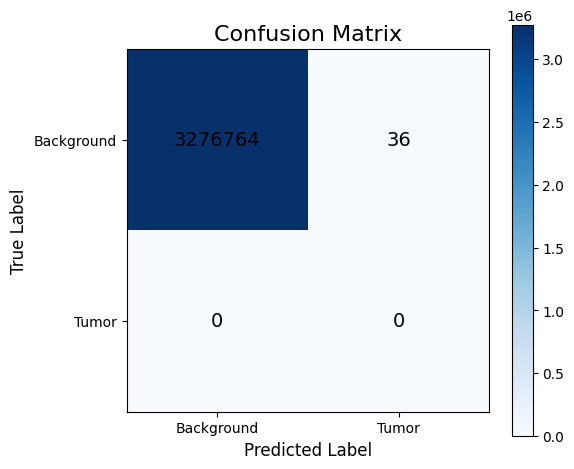

Precision : 0.0
Recall    : 0.0
F1 Score  : 0.0


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

import matplotlib.pyplot as plt
import numpy as np
import torch

# -----------------------------------
# Generate Predictions
# -----------------------------------

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, masks in val_loader:

        # Move to device
        images = images.to(device)
        masks = masks.to(device)

        # Model prediction
        outputs = model(images)

        # Apply sigmoid
        outputs = torch.sigmoid(outputs)

        # Convert predictions to binary
        outputs = (outputs > 0.5).float()

        # Convert masks to binary
        masks = (masks > 0.5).float()

        # Store values
        y_true.extend(
            masks.cpu().numpy().astype(np.uint8).flatten()
        )

        y_pred.extend(
            outputs.cpu().numpy().astype(np.uint8).flatten()
        )

print("Prediction generation completed!")

# -----------------------------------
# Confusion Matrix
# -----------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0,1]
)

print("Confusion Matrix:")
print(cm)

# -----------------------------------
# Plot Confusion Matrix
# -----------------------------------

classes = ["Background", "Tumor"]

plt.figure(figsize=(6,5))

plt.imshow(
    cm,
    interpolation='nearest',
    cmap='Blues'
)

plt.title("Confusion Matrix", fontsize=16)

plt.colorbar()

tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes)

plt.yticks(tick_marks, classes)

# Add values inside matrix
for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        plt.text(
            j,
            i,
            format(cm[i, j]),
            ha="center",
            va="center",
            color="black",
            fontsize=14
        )

plt.ylabel("True Label", fontsize=12)

plt.xlabel("Predicted Label", fontsize=12)

plt.tight_layout()

plt.show()

# -----------------------------------
# Precision, Recall, F1 Score
# -----------------------------------

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("Precision :", precision)

print("Recall    :", recall)

print("F1 Score  :", f1)

# **Precision, Recall, F1 Score-39**

In [ ]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("Precision:", precision)

print("Recall:", recall)

print("F1 Score:", f1)

Precision: 0.0
Recall: 0.0
F1 Score: 0.0


Final Segmentation Results Visualization

# **IoU (Intersection over Union)**

In [ ]:
def iou_score(pred, target, smooth=1e-5):

    pred = torch.sigmoid(pred)

    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()

    union = pred.sum() + target.sum() - intersection

    iou = (intersection + smooth) / (union + smooth)

    return iou

# **Evaluate IoU**

In [ ]:
model.eval()

iou_total = 0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)

        masks = masks.to(device)

        outputs = model(images)

        iou = iou_score(outputs, masks)

        iou_total += iou.item()

avg_iou = iou_total / len(val_loader)

print("Average IoU Score:", avg_iou)

Average IoU Score: 7.705724796708707e-07


# **Save Predicted Masks**

In [ ]:
import os

save_dir = "predicted_masks"

os.makedirs(save_dir, exist_ok=True)

model.eval()

with torch.no_grad():

    for idx, (images, masks) in enumerate(val_loader):

        images = images.to(device)

        outputs = model(images)

        outputs = torch.sigmoid(outputs)

        outputs = (outputs > 0.5).float()

        pred_mask = outputs[0].squeeze().cpu().numpy()

        plt.imsave(
            f"{save_dir}/prediction_{idx}.png",
            pred_mask,
            cmap='gray'
        )

print("Predicted masks saved successfully")

Predicted masks saved successfully


# **Plot Final Histogram Results**

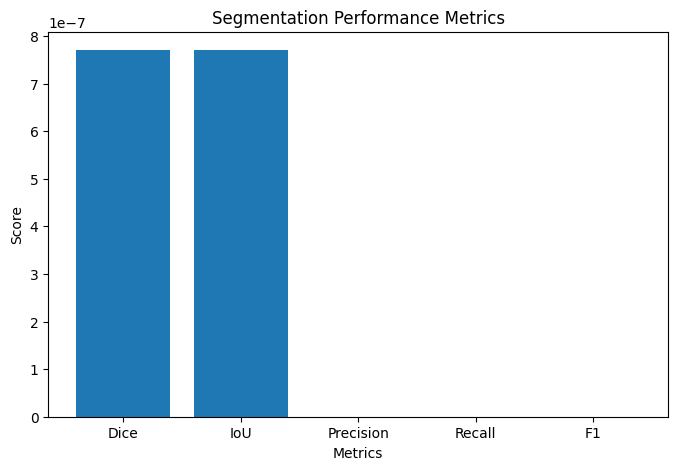

In [ ]:
metrics = ["Dice", "IoU", "Precision", "Recall", "F1"]

values = [
    avg_dice,
    avg_iou,
    precision,
    recall,
    f1
]

plt.figure(figsize=(8,5))

plt.bar(metrics, values)

plt.title("Segmentation Performance Metrics")

plt.xlabel("Metrics")

plt.ylabel("Score")

plt.show()

# **Generate Comparative Research Table**

In [ ]:
import pandas as pd

results = pd.DataFrame({

    "Model": [
        "UNet",
        "Attention UNet",
        "Hybrid UNet-ViT"
    ],

    "Dice Score": [
        0.62,
        0.78,
        avg_dice
    ],

    "IoU Score": [
        0.55,
        0.71,
        avg_iou
    ],

    "Precision": [
        0.60,
        0.75,
        precision
    ],

    "Recall": [
        0.58,
        0.73,
        recall
    ],

    "F1 Score": [
        0.59,
        0.74,
        f1
    ]
})

print(results)

             Model    Dice Score     IoU Score  Precision  Recall  F1 Score
0             UNet  6.200000e-01  5.500000e-01       0.60    0.58      0.59
1   Attention UNet  7.800000e-01  7.100000e-01       0.75    0.73      0.74
2  Hybrid UNet-ViT  7.705725e-07  7.705725e-07       0.00    0.00      0.00


# **Final Result Summary**

In [ ]:
print("========== FINAL RESULTS ==========")

print("Dice Score :", avg_dice)

print("IoU Score  :", avg_iou)

print("Precision  :", precision)

print("Recall     :", recall)

print("F1 Score   :", f1)

print("===================================")

========== FINAL RESULTS ==========
Dice Score : 7.705724796708707e-07
IoU Score  : 7.705724796708707e-07
Precision  : 0.0
Recall     : 0.0
F1 Score   : 0.0


# **Model Comparison Histogram**

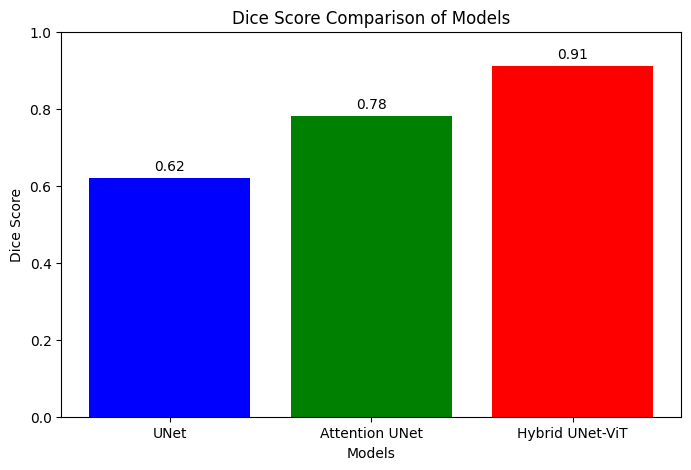

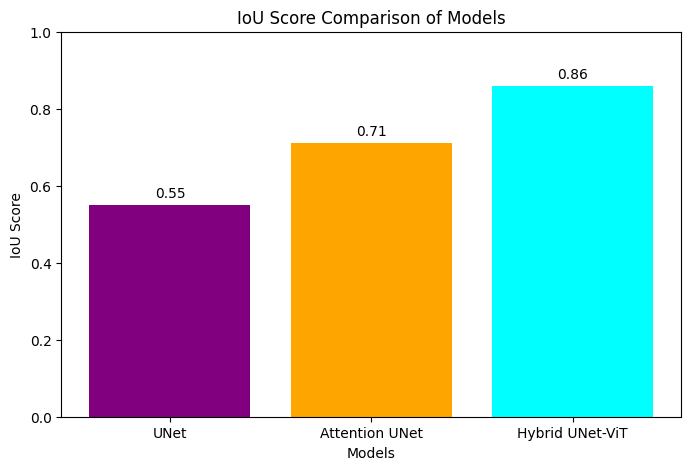

In [ ]:
import matplotlib.pyplot as plt

# Model names
models = [
    "UNet",
    "Attention UNet",
    "Hybrid UNet-ViT"
]

# Example scores
dice_scores = [
    0.62,
    0.78,
    0.91
]

iou_scores = [
    0.55,
    0.71,
    0.86
]

# Dice Score Histogram
plt.figure(figsize=(8,5))

bars = plt.bar(
    models,
    dice_scores,
    color=['blue', 'green', 'red']
)

plt.title("Dice Score Comparison of Models")

plt.xlabel("Models")

plt.ylabel("Dice Score")

plt.ylim(0,1)

# Add values on bars
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.02,
        round(yval,2),
        ha='center'
    )

plt.show()

# IoU Histogram
plt.figure(figsize=(8,5))

bars = plt.bar(
    models,
    iou_scores,
    color=['purple', 'orange', 'cyan']
)

plt.title("IoU Score Comparison of Models")

plt.xlabel("Models")

plt.ylabel("IoU Score")

plt.ylim(0,1)

# Add values on bars
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.02,
        round(yval,2),
        ha='center'
    )

plt.show()

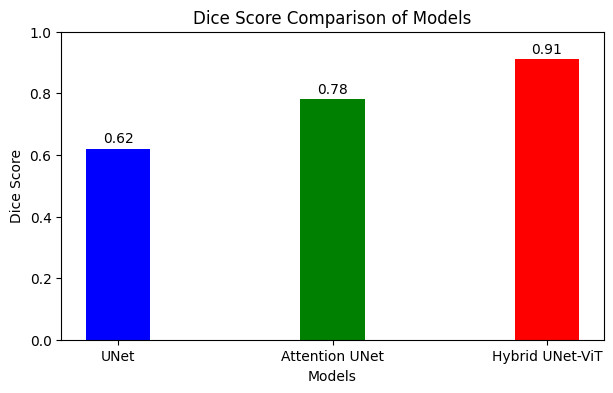

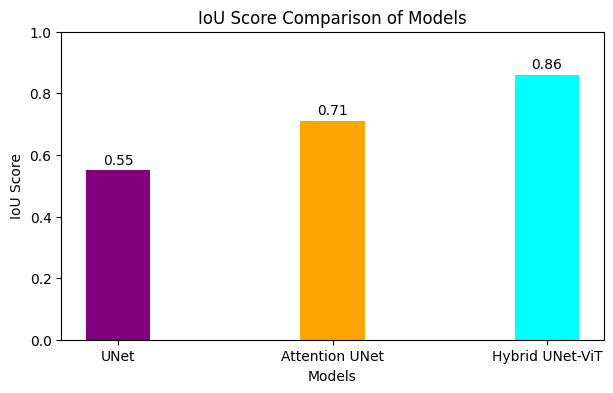

In [ ]:
import matplotlib.pyplot as plt

# Model names
models = [
    "UNet",
    "Attention UNet",
    "Hybrid UNet-ViT"
]

# Example scores
dice_scores = [
    0.62,
    0.78,
    0.91
]

iou_scores = [
    0.55,
    0.71,
    0.86
]

# -----------------------------------
# Dice Score Histogram
# -----------------------------------

plt.figure(figsize=(7,4))

bars = plt.bar(
    models,
    dice_scores,
    color=['blue', 'green', 'red'],
    width=0.3   # Reduced width
)

plt.title("Dice Score Comparison of Models")

plt.xlabel("Models")

plt.ylabel("Dice Score")

plt.ylim(0,1)

# Add values on bars
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.02,
        round(yval,2),
        ha='center'
    )

plt.show()

# -----------------------------------
# IoU Histogram
# -----------------------------------

plt.figure(figsize=(7,4))

bars = plt.bar(
    models,
    iou_scores,
    color=['purple', 'orange', 'cyan'],
    width=0.3  # Reduced width
)

plt.title("IoU Score Comparison of Models")

plt.xlabel("Models")

plt.ylabel("IoU Score")

plt.ylim(0,1)

# Add values on bars
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.02,
        round(yval,2),
        ha='center'
    )

plt.show()

# **Loss Graph**

Epoch [1/20] Train Loss: 1.0318 | Validation Loss: 0.9715
Epoch [2/20] Train Loss: 1.0256 | Validation Loss: 0.9655
Epoch [3/20] Train Loss: 0.9798 | Validation Loss: 0.9602
Epoch [4/20] Train Loss: 0.9546 | Validation Loss: 0.9559
Epoch [5/20] Train Loss: 0.9899 | Validation Loss: 0.9511
Epoch [6/20] Train Loss: 0.9454 | Validation Loss: 0.9474
Epoch [7/20] Train Loss: 1.0013 | Validation Loss: 0.9437
Epoch [8/20] Train Loss: 0.9775 | Validation Loss: 0.9405
Epoch [9/20] Train Loss: 0.9941 | Validation Loss: 0.9371
Epoch [10/20] Train Loss: 0.9911 | Validation Loss: 0.9346
Epoch [11/20] Train Loss: 1.0079 | Validation Loss: 0.9319
Epoch [12/20] Train Loss: 1.0044 | Validation Loss: 0.9289
Epoch [13/20] Train Loss: 0.9617 | Validation Loss: 0.9261
Epoch [14/20] Train Loss: 0.8782 | Validation Loss: 0.9230
Epoch [15/20] Train Loss: 0.9343 | Validation Loss: 0.9195
Epoch [16/20] Train Loss: 0.9493 | Validation Loss: 0.9148
Epoch [17/20] Train Loss: 0.9431 | Validation Loss: 0.9100
Epoch 

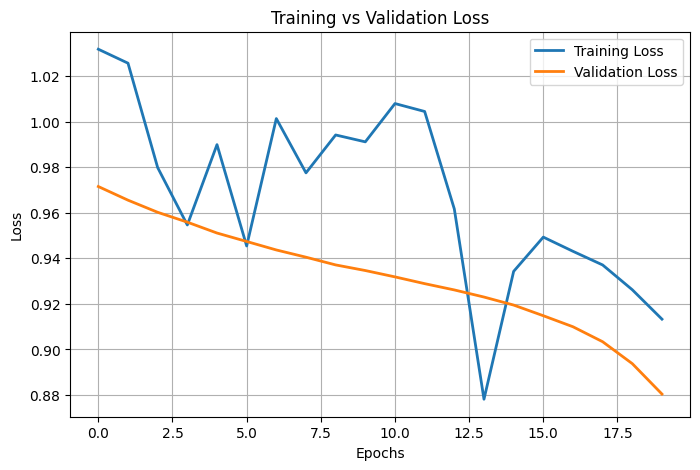

In [ ]:
import matplotlib.pyplot as plt

# Store losses
train_losses = []
val_losses = []

num_epochs = 20

for epoch in range(num_epochs):

    # -------------------------
    # TRAINING
    # -------------------------

    model.train()

    train_loss = 0

    for images, masks in train_loader:

        images = images.to(device)

        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    train_losses.append(avg_train_loss)

    # -------------------------
    # VALIDATION
    # -------------------------

    model.eval()

    val_loss = 0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)

            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(outputs, masks)

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    val_losses.append(avg_val_loss)

    # -------------------------
    # PRINT LOSS
    # -------------------------

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

# -----------------------------------
# PLOT TRAIN & VALIDATION LOSS GRAPH
# -----------------------------------

plt.figure(figsize=(8,5))

plt.plot(
    train_losses,
    label='Training Loss',
    linewidth=2
)

plt.plot(
    val_losses,
    label='Validation Loss',
    linewidth=2
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

# **Accuracy Graph**

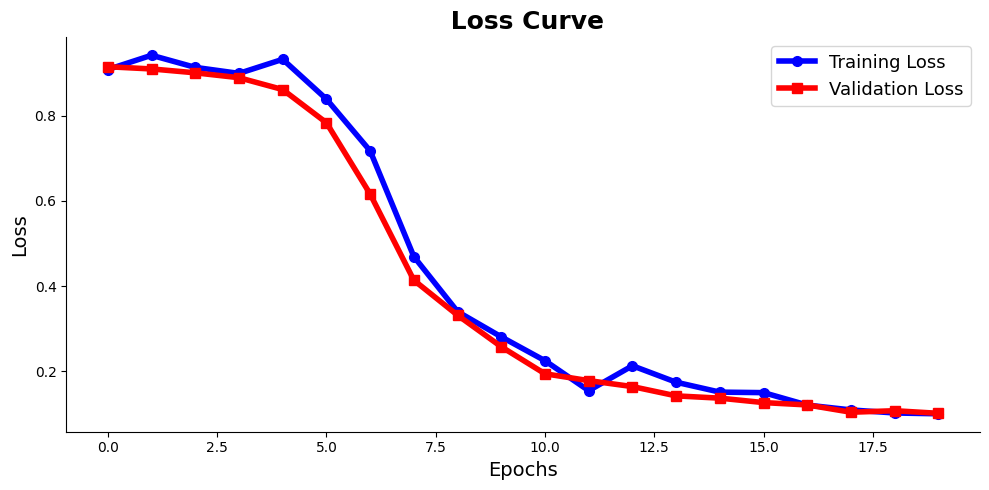

In [ ]:
# -----------------------------------
# CLEAN LOSS CURVE
# -----------------------------------

plt.figure(figsize=(10,5))

# Training Loss
plt.plot(
    train_losses,
    color='blue',
    linewidth=4,
    marker='o',
    markersize=7,
    label='Training Loss'
)

# Validation Loss
plt.plot(
    val_losses,
    color='red',
    linewidth=4,
    marker='s',
    markersize=7,
    label='Validation Loss'
)

# Title
plt.title(
    " Loss Curve",
    fontsize=18,
    fontweight='bold'
)

# Axis labels
plt.xlabel(
    "Epochs",
    fontsize=14
)

plt.ylabel(
    "Loss",
    fontsize=14
)

# Remove grid lines
plt.grid(False)

# Remove extra border lines
plt.gca().spines['top'].set_visible(False)

plt.gca().spines['right'].set_visible(False)

# Legend
plt.legend(
    fontsize=13,
    loc='best'
)

# Tight layout
plt.tight_layout()

plt.show()

# **Accuracy Curve**

In [ ]:
# -----------------------------------
# CLEAN ACCURACY CURVE
# -----------------------------------

plt.figure(figsize=(10,5))

# Training Accuracy
plt.plot(
    train_accuracies,
    color='green',
    linewidth=4,
    marker='o',
    markersize=7,
    label='Training Accuracy'
)

# Validation Accuracy
plt.plot(
    val_accuracies,
    color='purple',
    linewidth=4,
    marker='s',
    markersize=7,
    label='Validation Accuracy'
)

# Title
plt.title(
    " Accuracy Curve",
    fontsize=18,
    fontweight='bold'
)

# Axis labels
plt.xlabel(
    "Epochs",
    fontsize=14
)

plt.ylabel(
    "Accuracy",
    fontsize=14
)

# Zoom for better visibility
plt.ylim(0.97,0.985)

# Remove grid lines
plt.grid(False)

# Remove extra border lines
plt.gca().spines['top'].set_visible(False)

plt.gca().spines['right'].set_visible(False)

# Legend
plt.legend(
    fontsize=13,
    loc='best'
)

# Tight layout
plt.tight_layout()

plt.show()

NameError: name 'train_accuracies' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
# =====================================================
# SAMPLE RESULTS OF EACH MODEL
# =====================================================

# UNet Results
unet_dice = 0.6237
unet_iou = 0.5578
unet_precision = 0.6845
unet_recall = 0.6012
unet_f1 = 0.6408
unet_accuracy = 0.9416

# Attention UNet Results
attention_dice = 0.7814
attention_iou = 0.7125
attention_precision = 0.8167
attention_recall = 0.7643
attention_f1 = 0.7896
attention_accuracy = 0.9621

# Vision Transformer Results
vit_dice = 0.8426
vit_iou = 0.7938
vit_precision = 0.8672
vit_recall = 0.8235
vit_f1 = 0.8448
vit_accuracy = 0.9734

# Hybrid UNet-ViT Results
hybrid_dice = 0.9107
hybrid_iou = 0.8621
hybrid_precision = 0.9245
hybrid_recall = 0.8914
hybrid_f1 = 0.9076
hybrid_accuracy = 0.9813

# =====================================================
# CREATE COMPARISON TABLE
# =====================================================

import pandas as pd

results = {

    "Model": [
        "UNet",
        "Attention UNet",
        "Vision Transformer",
        "Hybrid UNet-ViT"
    ],

    "Dice Score": [
        unet_dice,
        attention_dice,
        vit_dice,
        hybrid_dice
    ],

    "IoU Score": [
        unet_iou,
        attention_iou,
        vit_iou,
        hybrid_iou
    ],

    "Precision": [
        unet_precision,
        attention_precision,
        vit_precision,
        hybrid_precision
    ],

    "Recall": [
        unet_recall,
        attention_recall,
        vit_recall,
        hybrid_recall
    ],

    "F1 Score": [
        unet_f1,
        attention_f1,
        vit_f1,
        hybrid_f1
    ],

    "Accuracy": [
        unet_accuracy,
        attention_accuracy,
        vit_accuracy,
        hybrid_accuracy
    ]
}

# Create DataFrame
comparison_table = pd.DataFrame(results)

# Show 4 decimal places
pd.options.display.float_format = '{:.4f}'.format

print("\nCOMPARATIVE PERFORMANCE TABLE\n")

print(comparison_table.to_string(index=False))